# Técnicas de ensamble (IE10)

Este notebook implementa y evalúa técnicas de ensamble (bagging, voting y stacking) sobre los modelos individuales optimizados por la Persona 1, usando la misma validación cruzada y métricas para garantizar comparabilidad.

In [16]:
import sys
from pathlib import Path

# Ruta a la raíz del proyecto (funciona desde la raíz o desde notebooks/)
RAIZ_PROYECTO = Path.cwd()
if RAIZ_PROYECTO.name == "notebooks":
    RAIZ_PROYECTO = RAIZ_PROYECTO.parent
sys.path.insert(0, str(RAIZ_PROYECTO))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

from src.train import (
    cargar_datos_crudos, crear_cv, calcular_metricas, metricas_por_fold,
    resumir_folds, construir_pipeline, construir_ridge_robusto,
    construir_boosting_es, construir_random_forest, construir_extra_trees,
    construir_voting, construir_stacking, cargar_mejores_parametros,
    fila_resultado, guardar_resultados, rangos_precio, error_por_grupo,
)

X_train, X_test, y_train, y_test = cargar_datos_crudos()
cv = crear_cv()
parametros = cargar_mejores_parametros()
parametros

{'ridge_robusto': {'alpha': 30.0,
  'recorte_z': 3.0,
  'log_objetivo': True,
  'MAE_CV_media': 14084.00684269003,
  'como_construirlo': 'construir_ridge_robusto(X, alpha=..., recorte_z=...)'},
 'boosting_optimizado': {'learning_rate': 0.03203913722293047,
  'max_iter': 500,
  'max_depth': 8,
  'max_leaf_nodes': 31,
  'min_samples_leaf': 5,
  'l2_regularization': 0.0,
  'loss': 'absolute_error',
  'early_stopping': True,
  'validation_fraction': 0.1,
  'n_iter_no_change': 30,
  'arboles_usados_modelo_final': 500,
  'MAE_CV_media': 14707.904207518595,
  'como_construirlo': 'construir_pipeline(construir_boosting_es(**parametros), X)'}}

## 1. Modelos individuales

Se construyen los modelos base (Ridge robusto, boosting optimizado, Random Forest y Extra Trees) usando los mejores hiperparámetros guardados por la Persona 1.

In [17]:
ridge_robusto = construir_ridge_robusto(
    X_train,
    alpha=parametros["ridge_robusto"]["alpha"],
    recorte_z=parametros["ridge_robusto"]["recorte_z"],
)

boosting_optimizado = construir_pipeline(
    construir_boosting_es(**parametros["boosting_optimizado"]),
    X_train,
)

random_forest = construir_pipeline(construir_random_forest(), X_train)
extra_trees = construir_pipeline(construir_extra_trees(), X_train)

## 2. Ensambles (Voting y Stacking)

Se combinan Ridge robusto, boosting optimizado y Random Forest mediante VotingRegressor (promedio ponderado) y StackingRegressor (meta-modelo Ridge con CV interna de 5 folds para evitar fuga de datos).

In [18]:
voting = construir_voting(
    X_train, pesos=[1, 1, 1], incluir_rf=True, parametros=parametros,
)

stacking = construir_stacking(
    X_train, meta_alpha=1.0, cv_interno=5, parametros=parametros,
)

## 3. Validación cruzada

Se evalúan los 6 modelos con la misma CV de 5 folds (semilla 42) usando MAE, RMSE, R² y cobertura ±10 %.

In [19]:
modelos = {
    "Ridge robusto": ridge_robusto,
    "Boosting optimizado": boosting_optimizado,
    "Random Forest": random_forest,
    "Extra Trees": extra_trees,
    "Voting": voting,
    "Stacking": stacking,
}

resultados_cv = []
for nombre, modelo in modelos.items():
    folds = metricas_por_fold(modelo, X_train, y_train, cv=cv)
    resumen = resumir_folds(folds)
    resultados_cv.append({"modelo": nombre, **resumen})

tabla_cv = pd.DataFrame(resultados_cv)
tabla_cv

,modelo,MAE_media,MAE_desv,RMSE_media,RMSE_desv,R2_media,R2_desv,Cobertura_10_media,Cobertura_10_desv,MAE_entrenamiento_media,MAE_entrenamiento_desv,R2_entrenamiento_media,R2_entrenamiento_desv
0,Ridge robusto,14084.006843,1094.904159,24098.952483,8562.956810,0.893070,0.082012,0.736353,0.018478,12798.615659,451.809164,0.928527,0.009974
1,Boosting optimizado,14707.904208,1688.191615,25593.810521,6333.916745,0.885026,0.054509,0.735915,0.020970,6692.968389,425.030407,0.958992,0.003619
2,Random Forest,16127.637211,1690.508035,26666.047974,6533.341523,0.874679,0.061101,0.695813,0.011744,5910.921308,142.473422,0.983504,0.002079
3,Extra Trees,16079.348131,1670.871259,27015.595068,6665.516612,0.871288,0.063082,0.693694,0.016867,0.000000,0.000000,1.000000,0.000000
4,Voting,13995.222848,1590.315140,24042.312965,7215.273051,0.896281,0.063266,0.748292,0.012182,7974.437152,113.531705,0.965832,0.003435
5,Stacking,13658.557606,1359.743970,24035.270717,8531.086117,0.893610,0.079558,0.753839,0.017952,9869.587466,869.054981,0.952963,0.006294


## 4. Mejora frente al mejor individual

Se calcula la mejora relativa del MAE de cada ensamble frente al mejor modelo individual (Ridge robusto o boosting optimizado).

In [20]:
mae_individual = tabla_cv.loc[
    tabla_cv["modelo"].isin(["Ridge robusto", "Boosting optimizado"]),
    "MAE_media",
].min()

tabla_cv["Mejora_MAE_vs_mejor_individual"] = (
    1 - tabla_cv["MAE_media"] / mae_individual
)

tabla_cv[[
    "modelo", "MAE_media", "MAE_desv", "RMSE_media", "R2_media",
    "Cobertura_10_media", "Mejora_MAE_vs_mejor_individual",
]]

,modelo,MAE_media,MAE_desv,RMSE_media,R2_media,Cobertura_10_media,Mejora_MAE_vs_mejor_individual
0,Ridge robusto,14084.006843,1094.904159,24098.952483,0.893070,0.736353,0.000000
1,Boosting optimizado,14707.904208,1688.191615,25593.810521,0.885026,0.735915,-0.044298
2,Random Forest,16127.637211,1690.508035,26666.047974,0.874679,0.695813,-0.145103
3,Extra Trees,16079.348131,1670.871259,27015.595068,0.871288,0.693694,-0.141674
4,Voting,13995.222848,1590.315140,24042.312965,0.896281,0.748292,0.006304
5,Stacking,13658.557606,1359.743970,24035.270717,0.893610,0.753839,0.030208


## 5. Comparación gráfica

Gráfico de barras del MAE en validación cruzada, con desviación estándar por fold.

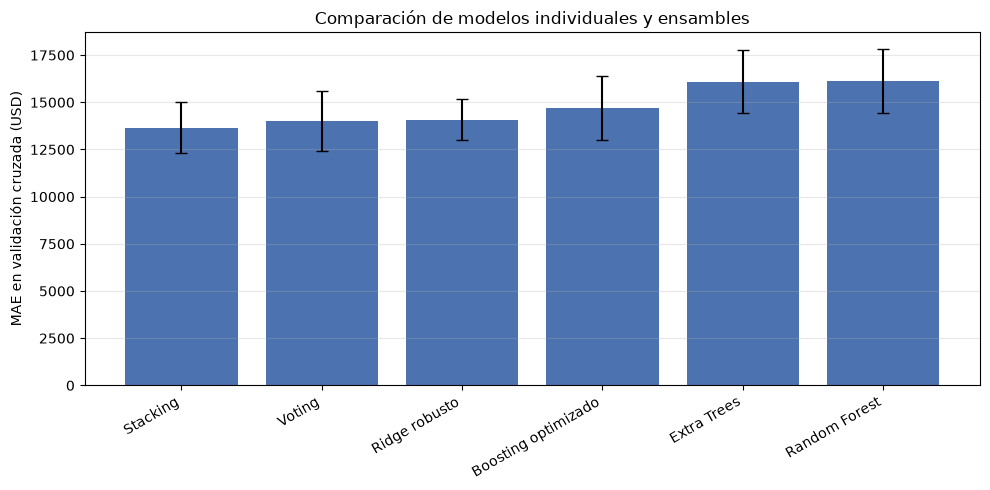

Figura guardada en: c:\Users\gpatr\Desktop\TrabajoHosuing\Proyecto_ML_housing\images\ensambles_comparacion_mae.png


In [21]:
ruta_imagen = RAIZ_PROYECTO / "images" / "ensambles_comparacion_mae.png"
ruta_imagen.parent.mkdir(parents=True, exist_ok=True)

orden = tabla_cv.sort_values("MAE_media")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(
    orden["modelo"], orden["MAE_media"], yerr=orden["MAE_desv"],
    capsize=4, color="#4C72B0",
)
ax.set_ylabel("MAE en validación cruzada (USD)")
ax.set_title("Comparación de modelos individuales y ensambles")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(ruta_imagen, dpi=150)
plt.show()

print(f"Figura guardada en: {ruta_imagen}")

## 6. Evaluación en prueba

Se reentrenan los 6 modelos con todo el entrenamiento y se evalúan en el conjunto de prueba (usado una única vez al final).

In [22]:
mae_referencia_prueba = np.median(y_train)
filas_prueba = []

for nombre, modelo in modelos.items():
    modelo_ajustado = clone(modelo).fit(X_train, y_train)
    metricas_prueba = calcular_metricas(y_test, modelo_ajustado.predict(X_test))
    metricas_cv_agregadas = {
        "MAE": tabla_cv.loc[tabla_cv["modelo"] == nombre, "MAE_media"].iloc[0],
        "RMSE": tabla_cv.loc[tabla_cv["modelo"] == nombre, "RMSE_media"].iloc[0],
        "R2": tabla_cv.loc[tabla_cv["modelo"] == nombre, "R2_media"].iloc[0],
        "Cobertura_10": tabla_cv.loc[tabla_cv["modelo"] == nombre, "Cobertura_10_media"].iloc[0],
    }
    filas_prueba.append(fila_resultado(
        nombre=nombre,
        familia="ensamble" if nombre in ["Voting", "Stacking"] else "individual",
        hiperparametros=parametros if nombre in ["Voting", "Stacking"] else {},
        m_cv=metricas_cv_agregadas,
        m_prueba=metricas_prueba,
        mae_referencia_prueba=mae_referencia_prueba,
    ))

tabla_final = pd.DataFrame(filas_prueba)
tabla_final

,modelo,familia,hiperparametros,MAE_CV,RMSE_CV,R2_CV,Cobertura10_CV,MAE_prueba,RMSE_prueba,R2_prueba,Cobertura10_prueba,Mejora_MAE_prueba,Cumple_meta_cobertura,Cumple_meta_mejora,seleccionado
0,Ridge robusto,individual,{},14084.006843,24098.952483,0.893070,0.736353,14085.894162,27557.826097,0.905279,0.771331,0.911963,True,True,False
1,Boosting optimizado,individual,{},14707.904208,25593.810521,0.885026,0.735915,13386.729345,24046.915078,0.927876,0.778157,0.916333,True,True,False
2,Random Forest,individual,{},16127.637211,26666.047974,0.874679,0.695813,15705.892491,26818.263064,0.910294,0.725256,0.901838,True,True,False
3,Extra Trees,individual,{},16079.348131,27015.595068,0.871288,0.693694,15763.747480,26804.742624,0.910385,0.720137,0.901477,True,True,False
4,Voting,ensamble,"{""ridge_robusto"": {""alpha"": 30.0, ""recorte_z"":...",13995.222848,24042.312965,0.896281,0.748292,13362.749575,24803.971574,0.923264,0.776451,0.916483,True,True,False
5,Stacking,ensamble,"{""ridge_robusto"": {""alpha"": 30.0, ""recorte_z"":...",13658.557606,24035.270717,0.893610,0.753839,13108.263043,25081.688609,0.921536,0.798635,0.918073,True,True,False


## 7. Análisis por rango de precio

Se reentrena el Stacking (mejor modelo) y se analiza el error por cuartil de precio, con foco en Q1 (el más débil históricamente).

In [23]:
stacking_ajustado = clone(stacking).fit(X_train, y_train)
y_pred_stacking = stacking_ajustado.predict(X_test)

resultados_stacking = pd.DataFrame({
    "y_real": y_test.values,
    "y_pred": y_pred_stacking,
})
resultados_stacking["rango_precio"] = rangos_precio(y_train, y_test.values)

tabla_cuartiles = error_por_grupo(resultados_stacking, "rango_precio")
tabla_cuartiles

,rango_precio,n,MAE,Error_rel_mediano,Cobertura_10,Muestra_suficiente
0,"Q4: más de 210,000",183,20322.309947,0.049224,0.803279,True
1,"Q2: 129,000-160,000",142,8610.087955,0.042736,0.859155,True
2,"Q1: hasta 129,000",139,8997.035886,0.066859,0.654676,True
3,"Q3: 160,000-210,000",122,12206.876600,0.042803,0.885246,True


## 8. Análisis por segmento (S1–S5)

Se cruza el desempeño del Stacking con los segmentos generados por clustering (notebook 03).

In [24]:
clusters = pd.read_csv(
    RAIZ_PROYECTO / "data" / "processed" / "clusters.csv"
)

indices_test = X_test.index
clusters_test = clusters.loc[clusters.index.isin(indices_test)]

resultados_stacking["segmento"] = clusters_test["segmento"].values

tabla_segmentos = error_por_grupo(resultados_stacking, "segmento", min_n=10)
tabla_segmentos

,segmento,n,MAE,Error_rel_mediano,Cobertura_10,Muestra_suficiente
0,"S3 Un piso de tamaño medio, construcción de lo...",151,12540.916729,0.043255,0.814570,True
1,"S5 Dos pisos amplias, construcción reciente",142,11633.917312,0.049412,0.852113,True
2,S2 Antiguas y compactas,135,11784.027142,0.051675,0.762963,True
3,S4 Un piso de construcción reciente y mayor ca...,132,16562.951505,0.048460,0.772727,True
4,S1 Dúplex y multifamiliares,26,13792.084468,0.063066,0.730769,True


## 9. Guardar resultados

Se guardan los ensambles en `results_ensambles.csv` y se actualiza `results_supervised.csv` (consumido por la Persona 3).

In [ ]:
# Guardar ensambles en archivo propio
ruta_ensambles = RAIZ_PROYECTO / "models" / "results_ensambles.csv"
ruta_ensambles.parent.mkdir(parents=True, exist_ok=True)
guardar_resultados(tabla_final, ruta=ruta_ensambles)

# Actualizar results_supervised.csv sin duplicar ensambles
ruta_supervised = RAIZ_PROYECTO / "models" / "results_supervised.csv"

# Modelos que este notebook aporta (para identificarlos y reemplazarlos)
modelos_ensamble = [
    "Ridge robusto",
    "Boosting optimizado",
    "Random Forest",
    "Extra Trees",
    "Voting",
    "Stacking",
]

# Carga el CSV existente (si existe)
if ruta_supervised.exists():
    resultados_existentes = pd.read_csv(ruta_supervised)
    # Elimina filas previas de tus ensambles (para reemplazar, no duplicar)
    resultados_existentes = resultados_existentes[
        ~resultados_existentes["modelo"].isin(modelos_ensamble)
    ]
else:
    resultados_existentes = pd.DataFrame(columns=tabla_final.columns)

# Concatena: modelos existentes (sin tus ensambles) + tus ensambles nuevos
resultados_actualizados = pd.concat(
    [resultados_existentes, tabla_final],
    ignore_index=True,
)

# Guarda sobrescribiendo
guardar_resultados(
    resultados_actualizados,
    ruta=ruta_supervised,
)

resultados_actualizados

,modelo,familia,hiperparametros,MAE_CV,RMSE_CV,R2_CV,Cobertura10_CV,MAE_prueba,RMSE_prueba,R2_prueba,Cobertura10_prueba,Mejora_MAE_prueba,Cumple_meta_cobertura,Cumple_meta_mejora,seleccionado
0,Referencia (mediana),Predicción constante,"{""valor"": ""mediana de SalePrice del entrenamie...",54122.839590,79368.820622,-0.059483,0.209044,63838.100683,94322.624866,-0.109661,0.186007,NaN,NaN,NaN,False
1,Ridge base,Lineal regularizado (log1p del objetivo),"{""alpha"": 1.0}",16064.398992,69346.107024,0.191205,0.712031,14940.413403,32245.569560,0.870312,0.750853,0.765964,True,True,False
2,Ridge ajustado,Lineal regularizado (log1p del objetivo),"{""modelo__regressor__alpha"": 1}",16064.398992,69346.107024,0.191205,0.712031,14940.413403,32245.569560,0.870312,0.750853,0.765964,True,True,False
3,Boosting base,Ensamble: gradient boosting,"{""configuracion"": ""por defecto""}",14916.655581,25179.604626,0.893367,0.722270,15623.869249,27026.955659,0.908893,0.742321,0.755258,True,True,False
4,Boosting ajustado,Ensamble: gradient boosting,"{""modelo__l2_regularization"": 1.0, ""modelo__le...",14634.924306,24996.798042,0.894910,0.732082,15349.591878,27284.700589,0.907147,0.747440,0.759554,True,True,True
5,Ridge robusto,individual,{},14084.006843,24098.952483,0.893070,0.736353,14085.894162,27557.826097,0.905279,0.771331,0.911963,True,True,False
6,Boosting optimizado,individual,{},14707.904208,25593.810521,0.885026,0.735915,13386.729345,24046.915078,0.927876,0.778157,0.916333,True,True,False
7,Random Forest,individual,{},16127.637211,26666.047974,0.874679,0.695813,15705.892491,26818.263064,0.910294,0.725256,0.901838,True,True,False
8,Extra Trees,individual,{},16079.348131,27015.595068,0.871288,0.693694,15763.747480,26804.742624,0.910385,0.720137,0.901477,True,True,False
9,Voting,ensamble,"{""ridge_robusto"": {""alpha"": 30.0, ""recorte_z"":...",13995.222848,24042.312965,0.896281,0.748292,13362.749575,24803.971574,0.923264,0.776451,0.916483,True,True,False


In [1]:
import pandas as pd
from pathlib import Path

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

ruta_csv = raiz / "models" / "results_supervised.csv"

# Carga el CSV con duplicados
df = pd.read_csv(ruta_csv)

# Elimina duplicados exactos (mantiene la primera aparición)
df_sin_duplicados = df.drop_duplicates(
    subset=["modelo", "familia", "MAE_CV", "MAE_prueba"],
    keep="first",
)

# Verifica cuántas filas quedan
print(f"Filas antes: {len(df)}")
print(f"Filas después: {len(df_sin_duplicados)}")

# Guarda sobrescribiendo
df_sin_duplicados.to_csv(ruta_csv, index=False)

df_sin_duplicados

Filas antes: 17
Filas después: 11


,modelo,familia,hiperparametros,MAE_CV,RMSE_CV,R2_CV,Cobertura10_CV,MAE_prueba,RMSE_prueba,R2_prueba,Cobertura10_prueba,Mejora_MAE_prueba,Cumple_meta_cobertura,Cumple_meta_mejora,seleccionado
0,Referencia (mediana),Predicción constante,"{""valor"": ""mediana de SalePrice del entrenamie...",54122.839590,79368.820622,-0.059483,0.209044,63838.100683,94322.624866,-0.109661,0.186007,NaN,NaN,NaN,False
1,Ridge base,Lineal regularizado (log1p del objetivo),"{""alpha"": 1.0}",16064.398992,69346.107024,0.191205,0.712031,14940.413403,32245.569560,0.870312,0.750853,0.765964,True,True,False
2,Ridge ajustado,Lineal regularizado (log1p del objetivo),"{""modelo__regressor__alpha"": 1}",16064.398992,69346.107024,0.191205,0.712031,14940.413403,32245.569560,0.870312,0.750853,0.765964,True,True,False
3,Boosting base,Ensamble: gradient boosting,"{""configuracion"": ""por defecto""}",14916.655581,25179.604626,0.893367,0.722270,15623.869249,27026.955659,0.908893,0.742321,0.755258,True,True,False
4,Boosting ajustado,Ensamble: gradient boosting,"{""modelo__l2_regularization"": 1.0, ""modelo__le...",14634.924306,24996.798042,0.894910,0.732082,15349.591878,27284.700589,0.907147,0.747440,0.759554,True,True,True
5,Ridge robusto,individual,{},14084.006843,24098.952483,0.893070,0.736353,14085.894162,27557.826097,0.905279,0.771331,0.911963,True,True,False
6,Boosting optimizado,individual,{},14707.904208,25593.810521,0.885026,0.735915,13386.729345,24046.915078,0.927876,0.778157,0.916333,True,True,False
7,Random Forest,individual,{},16127.637211,26666.047974,0.874679,0.695813,15705.892491,26818.263064,0.910294,0.725256,0.901838,True,True,False
8,Extra Trees,individual,{},16079.348131,27015.595068,0.871288,0.693694,15763.747480,26804.742624,0.910385,0.720137,0.901477,True,True,False
9,Voting,ensamble,"{""ridge_robusto"": {""alpha"": 30.0, ""recorte_z"":...",13995.222848,24042.312965,0.896281,0.748292,13362.749575,24803.971574,0.923264,0.776451,0.916483,True,True,False
